# Коллективные режимы волновой энергетической фермы — вариант 5
**Набор данных:** UCI Wave Energy Converters, сценарий Sydney (дополнительно — Perth).
**Вопрос:** можно ли описать распределение поглощаемой мощности между 16 преобразователями малым числом латентных факторов?
**Методы:** PCA и NMF при размерностях 2, 4, 8 (NMF — только на неотрицательных исходных мощностях `P1…P16`); качество восстановления на отложенных компоновках и устойчивость факторов.

## 1. Данные, ограничения постановки и ожидания

Файлы без заголовков, 49 столбцов: `X1…X16` и `Y1…Y16` (координаты 16 преобразователей CETO в области 566 × 566 м), `P1…P16` (мощность каждого преобразователя; в карточке набора единицы не указаны, значения ~10⁵ — вероятно, Вт), `Powerall` (суммарная мощность фермы). В сценарии 72 000 компоновок, подобранных алгоритмами эволюционной оптимизации.

**Ограничения из задания.** Входы — только `P1…P16`; координаты и `Powerall` — лишь для интерпретации, не входят в факторное пространство. Для PCA — не более 5 000 компоновок одного сценария.

**Что важно учесть: компоновки получены оптимизацией.** Это не независимая выборка из «естественного» распределения. 
1) Идущие подряд строки файла — шаги одной траектории оптимизатора и похожи (автокорреляция `Powerall` между соседями ≈ 0.66), поэтому случайное разбиение строк даёт утечку; отложенные компоновки берём **блоками подряд идущих строк**.
2) Оптимизатор сдвигает все компоновки в область высокой мощности, так что разброс мощностей мал (≈ 7 % от среднего) — для PCA это важно (центрирование убирает основную часть сигнала).

**Ожидания, сформулированные до моделирования (проверяются в §6–§8).**
* **H1 (общий режим).** Есть фактор с примерно одинаковыми нагрузками на все преобразователи, чей коэффициент почти совпадает с `Powerall`. *Опровержение:* ведущая компонента не похожа на «единичный» вектор, а корреляция её счёта с `Powerall` невелика.
* **H2 (режим неравномерности).** Существует фактор, отвечающий за перераспределение между преобразователями; его коэффициент коррелирует с коэффициентом вариации мощностей в компоновке. *Опровержение:* никакой из факторов не связан с неравномерностью.
* **H3 (индекс ≠ положение).** Номер преобразователя — произвольная метка (положения в разных компоновках разные), поэтому факторы по индексу не могут быть пространственными модами, а при почти одинаковых собственных значениях их направления неустойчивы. *Опровержение:* нагрузки факторов по индексам устойчивы между подвыборками, а остатки реконструкции не связаны с координатами.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA, NMF
from sklearn.model_selection import GroupKFold

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
SEED = 42; NS = 16
names = [f'X{i}' for i in range(1, 17)] + [f'Y{i}' for i in range(1, 17)] + [f'P{i}' for i in range(1, 17)] + ['Powerall']
def load(city):
    return pd.read_csv(f'{city}_Data.csv', header=None, names=names)   # файлы рядом с ноутбуком
raw = load('Sydney')
print(raw.shape, '| пропусков:', int(raw.isna().sum().sum()))
print('Powerall = ΣP: макс. отн. расхождение %.4f' % (np.abs(raw.Powerall - raw[[f'P{i}' for i in range(1, 17)]].sum(1)) / raw.Powerall).max())
print('автокорреляция Powerall при сдвиге 1 строка: %.2f; 1000 строк: %.2f' % (raw.Powerall.autocorr(1), raw.Powerall.autocorr(1000)))

(72000, 49) | пропусков: 0
Powerall = ΣP: макс. отн. расхождение 0.0028
автокорреляция Powerall при сдвиге 1 строка: 0.66; 1000 строк: 0.12


## 2. Подвыборка и разбиение

Воспроизводимая подвыборка из 5 000 компоновок (seed = 42). Разбиение — по **блокам** по 1000 подряд идущих строк исходного файла: ~30 % блоков целиком уходят в тест. Отложенные компоновки не участвуют ни в выборе размерности, ни в обучении.

Масштаб: мощности делим на 10⁵ (единицы ≈ 100 кВт). Стандартизацию к единичной дисперсии **не** применяем: все `Pi` в одних единицах, а для NMF нужны неотрицательные исходные значения. PCA центрируем по среднему обучающей части.

In [2]:
def make_sample(df, n=5000, seed=SEED, block=1000, test_frac=0.3):
    rng = np.random.default_rng(seed)
    idx = np.sort(rng.choice(len(df), n, replace=False))
    groups = idx // block
    ub = np.unique(groups); rb = np.random.default_rng(seed + 1)
    test_b = set(rb.choice(ub, int(round(test_frac * len(ub))), replace=False))
    is_te = np.array([g in test_b for g in groups])
    return idx, groups, is_te

idx, groups, is_te = make_sample(raw)
cols_P = [f'P{i}' for i in range(1, 17)]
sub = raw.iloc[idx]
Z = sub[cols_P].values / 1e5                      # 5000 × 16, неотрицательные мощности
Xc, Yc = sub[[f'X{i}' for i in range(1, 17)]].values, sub[[f'Y{i}' for i in range(1, 17)]].values   # только для интерпретации
pa = sub.Powerall.values / 1e5
Ztr, Zte, gtr = Z[~is_te], Z[is_te], groups[~is_te]
print('всего %d | train %d (блоков %d) | test %d (блоков %d)' % (len(Z), len(Ztr), len(np.unique(gtr)), len(Zte), len(np.unique(groups[is_te]))))
print('среднее по преобразователям: %.3f, sd внутри столбца: %.3f (%.1f%% от среднего)' % (Ztr.mean(), Ztr.std(0).mean(), 100 * Ztr.std(0).mean() / Ztr.mean()))

всего 5000 | train 3533 (блоков 50) | test 1467 (блоков 22)
среднее по преобразователям: 0.929, sd внутри столбца: 0.069 (7.4% от среднего)


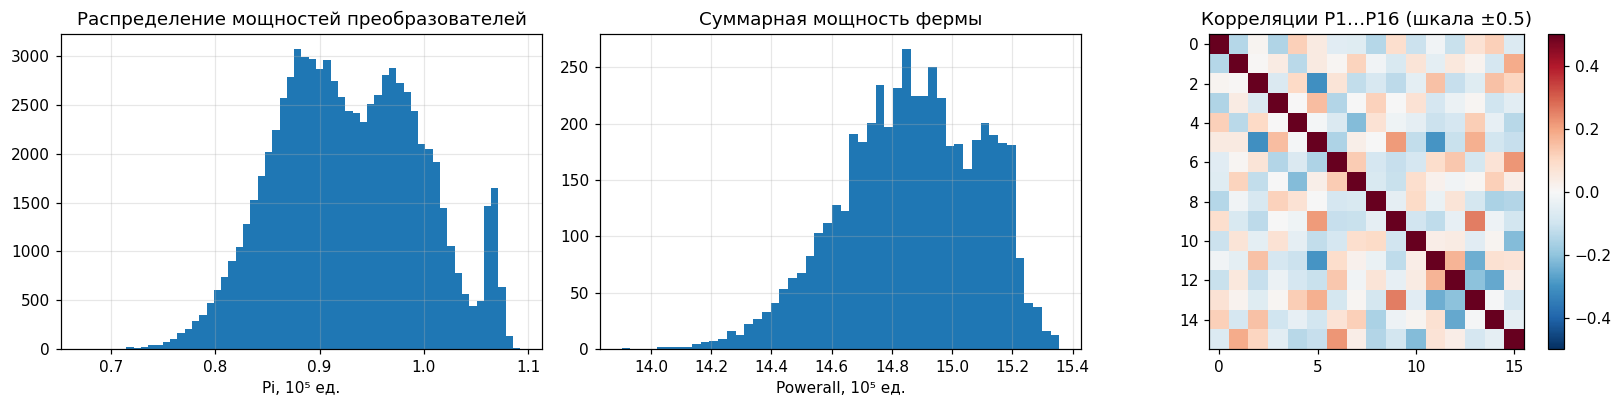

внедиагональные корреляции: среднее -0.020, sd 0.110, min -0.31, max 0.25


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(Z.ravel(), bins=60); ax[0].set_xlabel('Pi, 10⁵ ед.'); ax[0].set_title('Распределение мощностей преобразователей')
ax[1].hist(pa, bins=50); ax[1].set_xlabel('Powerall, 10⁵ ед.'); ax[1].set_title('Суммарная мощность фермы')
C_ = np.corrcoef(Ztr.T); im = ax[2].imshow(C_, cmap='RdBu_r', vmin=-.5, vmax=.5); ax[2].grid(False); plt.colorbar(im, ax=ax[2])
ax[2].set_title('Корреляции P1…P16 (шкала ±0.5)')
plt.tight_layout(); plt.show()
off = C_[np.triu_indices(16, 1)]
print('внедиагональные корреляции: среднее %.3f, sd %.3f, min %.2f, max %.2f' % (off.mean(), off.std(), off.min(), off.max()))

**Что видно.** Мощности разных преобразователей почти некоррелированы (среднее значение внедиагональной корреляции около нуля, чуть отрицательное: если одному преобразователю досталось больше, другим чуть меньше). Это уже предупреждает: общей низкоразмерной структуры «по индексам» может не быть.

## 3. Модели и метрики качества восстановления

Сравниваем при k = 2, 4, 8:
* **PCA** (с центрированием; фактически «среднее + k компонент»);
* **SVD без центрирования** — ранг-k приближение той же ранговой сложности, что и NMF (нужно для честного сравнения: теорема Эккарта–Янга–Мирского даёт для него нижнюю границу ошибки любой ранг-k факторизации, в том числе NMF);
* **NMF** (`init='nndsvda'`, `solver='cd'`, `max_iter=2000`) на неотрицательных Pi. Для новых компоновок коэффициенты находятся при фиксированных факторах (неотрицательная задача наименьших квадратов).

Метрики на матрице компоновок X (n × 16):
* **относительная ошибка** ‖X − X̂‖_F / ‖X‖_F — для NMF и PCA «выглядит» малой из-за большого среднего, поэтому ещё:
* **R²_rec = 1 − ‖X − X̂‖²_F / ‖X − μ‖²_F**, где μ — вектор средних обучающей части (качество относительно тривиального предсказания «средняя мощность каждого преобразователя»);
* **RMSE**, пересчитанный в проценты от средней мощности.

In [4]:
def fit_recon(method, k, Xtr_):
    # возвращает (функция восстановления X → X̂, матрица факторов k×16)
    if method == 'PCA':
        m = PCA(k, svd_solver='full').fit(Xtr_); return (lambda X: m.inverse_transform(m.transform(X))), m.components_
    if method == 'SVD (без центр.)':
        _, _, Vt = np.linalg.svd(Xtr_, full_matrices=False); V = Vt[:k]; return (lambda X: X @ V.T @ V), V
    if method == 'NMF':
        m = NMF(k, init='nndsvda', solver='cd', max_iter=2000, tol=1e-6, random_state=0).fit(Xtr_)
        return (lambda X: m.inverse_transform(m.transform(X))), m.components_
METHODS = ['PCA', 'SVD (без центр.)', 'NMF']

def rec_metrics(X, Xh, mu):
    sse = ((X - Xh) ** 2).sum()
    return {'rel_err': np.sqrt(sse / (X ** 2).sum()), 'R2_rec': 1 - sse / ((X - mu) ** 2).sum(),
            'RMSE_%': 100 * np.sqrt(((X - Xh) ** 2).mean()) / X.mean()}

# самопроверка: ранг-k SVD-приближение даёт нижнюю границу ошибки; при k=16 всё восстанавливается точно
mu_tr = Ztr.mean(0)
for k in [2, 4, 8, 16]:
    e = {m: rec_metrics(Zte, fit_recon(m, k, Ztr)[0](Zte), mu_tr)['R2_rec'] for m in METHODS}
    print(k, {m: round(v, 4) for m, v in e.items()})

2 {'PCA': 0.1501, 'SVD (без центр.)': 0.1132, 'NMF': 0.1134}
4 {'PCA': 0.3359, 'SVD (без центр.)': 0.2911, 'NMF': 0.291}
8 {'PCA': 0.6338, 'SVD (без центр.)': 0.6083, 'NMF': 0.6081}
16 {'PCA': 1.0, 'SVD (без центр.)': 1.0, 'NMF': 0.9997}


8 {'PCA': np.float64(0.6338), 'SVD (без центр.)': np.float64(0.6083), 'NMF': np.float64(0.6081)}


16 {'PCA': np.float64(1.0), 'SVD (без центр.)': np.float64(1.0), 'NMF': np.float64(0.9997)}


## 4. Выбор размерности по групповой кросс-валидации (только обучение)

5-fold CV по блокам (`GroupKFold`): ошибка восстановления на отложенном фолде для k = 1…16. Тест здесь не используется.

In [6]:
ks = list(range(1, 17)); gkf = GroupKFold(5)
cv_res = {m: {k: [] for k in ks} for m in METHODS}
for tr_i, va_i in gkf.split(Ztr, groups=gtr):
    mu = Ztr[tr_i].mean(0)
    for m in METHODS:
        for k in ks:
            f, _ = fit_recon(m, k, Ztr[tr_i]); cv_res[m][k].append(rec_metrics(Ztr[va_i], f(Ztr[va_i]), mu)['R2_rec'])
cv_tab = pd.DataFrame({m: {k: np.mean(v) for k, v in cv_res[m].items()} for m in METHODS})
cv_sd = pd.DataFrame({m: {k: np.std(v, ddof=1) for k, v in cv_res[m].items()} for m in METHODS})
print('CV R²_rec (среднее по 5 фолдам):'); cv_tab.round(3).T

CV R²_rec (среднее по 5 фолдам):


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
PCA,0.120,0.216,0.306,0.382,0.458,0.517,0.582,0.645,0.699,0.746,0.791,0.838,0.880,0.926,0.96,1.000
SVD (без центр.),0.043,0.163,0.260,0.347,0.428,0.500,0.559,0.624,0.684,0.741,0.788,0.836,0.882,0.922,0.96,1.000
NMF,0.043,0.163,0.259,0.348,0.427,0.499,0.559,0.623,0.684,0.741,0.788,0.836,0.882,0.922,0.96,0.999


In [7]:
# наименьшее k, при котором CV R²_rec ≥ 0.90 (доля «не-средней» дисперсии, объяснённая восстановлением)
for m in METHODS:
    ok = cv_tab.index[cv_tab[m] >= 0.90]; print(f'{m:18s} k* (R²_rec ≥ 0.90):', ok.min() if len(ok) else '> 16')
print('Рост CV R²_rec на один фактор (PCA): ', np.diff(cv_tab['PCA'].values).round(3))

PCA                k* (R²_rec ≥ 0.90): 14
SVD (без центр.)   k* (R²_rec ≥ 0.90): 14
NMF                k* (R²_rec ≥ 0.90): 14
Рост CV R²_rec на один фактор (PCA):  [0.096 0.089 0.076 0.076 0.06  0.065 0.063 0.054 0.047 0.045 0.047 0.041
 0.046 0.035 0.04 ]


**Размерность.** Выигрыш по ошибке от каждой следующей компоненты почти постоянный — **излома («локтя») нет**. Это означает, что структура мощностей не сводится к малому числу факторов: чтобы объяснить 90 % разброса вокруг среднего, нужно 14 из 16 компонент. Поэтому из предписанных k = 2, 4, 8 по CV «лучшим» всегда окажется 8 просто потому, что оно больше; выбирать k по излому нечем. Ниже даём тестовые ошибки для всех трёх размерностей.

## 5. Ошибка восстановления на отложенных компоновках (тест)

In [8]:
rows = []
for k in [2, 4, 8, 16]:
    for m in METHODS:
        f, _ = fit_recon(m, k, Ztr)
        for part, X_ in [('train', Ztr), ('test', Zte)]:
            r = rec_metrics(X_, f(X_), mu_tr); rows.append({'k': k, 'метод': m, 'выборка': part, **r})
        rows[-1]['CV R2_rec'] = cv_tab.loc[k, m]; rows[-2]['CV R2_rec'] = cv_tab.loc[k, m]
res = pd.DataFrame(rows)
tab = res.pivot_table(index=['k', 'метод'], columns='выборка', values=['rel_err', 'R2_rec', 'RMSE_%'])
tab.columns = [f'{a} {b}' for a, b in tab.columns]
tab['R2_rec CV'] = [cv_tab.loc[k, m] for k, m in tab.index]
tab[['rel_err train', 'rel_err test', 'R2_rec train', 'R2_rec CV', 'R2_rec test', 'RMSE_% test']].round(3)

rel_err train  rel_err test  R2_rec train  R2_rec CV  \
k  метод                                                                    
2  NMF                       0.067         0.070         0.177      0.163   
   PCA                       0.064         0.069         0.241      0.216   
   SVD (без центр.)          0.067         0.070         0.177      0.163   
4  NMF                       0.058         0.063         0.380      0.348   
   PCA                       0.056         0.061         0.419      0.382   
   SVD (без центр.)          0.058         0.063         0.381      0.347   
8  NMF                       0.043         0.047         0.656      0.623   
   PCA                       0.042         0.045         0.669      0.645   
   SVD (без центр.)          0.043         0.047         0.656      0.624   
16 NMF                       0.001         0.001         1.000      0.999   
   PCA                       0.000         0.000         1.000      1.000   
   SVD (без центр.)          0.000         0.000         1.000      1.000   

                     R2_rec test  RMSE_% test  
k  метод                                       
2  NMF                     0.113        7.021  
   PCA                     0.150        6.874  
   SVD (без центр.)        0.113        7.022  
4  NMF                     0.291        6.279  
   PCA                     0.336        6.077  
   SVD (без центр.)        0.291        6.278  
8  NMF                     0.608        4.668  
   PCA                     0.634        4.513  
   SVD (без центр.)        0.608        4.667  
16 NMF                     1.000        0.138  
   PCA                     1.000        0.000  
   SVD (без центр.)        1.000        0.000

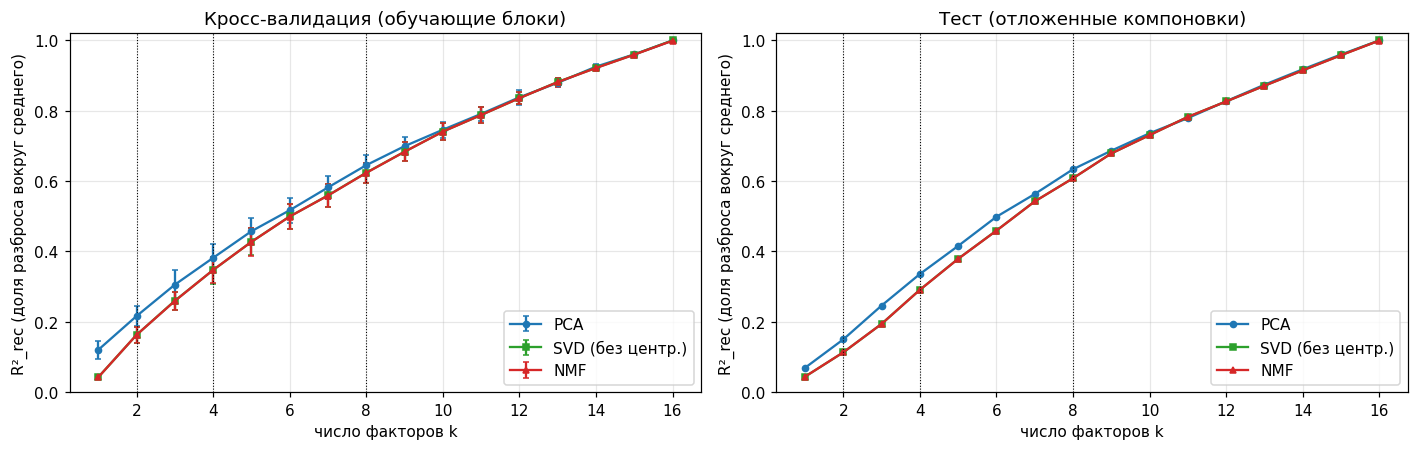

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sty = {'PCA': ('tab:blue', 'o'), 'SVD (без центр.)': ('tab:green', 's'), 'NMF': ('tab:red', '^')}
te_curve = {m: [rec_metrics(Zte, fit_recon(m, k, Ztr)[0](Zte), mu_tr)['R2_rec'] for k in ks] for m in METHODS}
for m in METHODS:
    c, mk = sty[m]
    ax[0].errorbar(ks, cv_tab[m], cv_sd[m], c=c, marker=mk, ms=4, capsize=2, label=m)
    ax[1].plot(ks, te_curve[m], c=c, marker=mk, ms=4, label=m)
for a, t in zip(ax, ['Кросс-валидация (обучающие блоки)', 'Тест (отложенные компоновки)']):
    for kk in [2, 4, 8]: a.axvline(kk, c='k', ls=':', lw=.7)
    a.set_xlabel('число факторов k'); a.set_ylabel('R²_rec (доля разброса вокруг среднего)'); a.set_title(t); a.set_ylim(0, 1.02); a.legend()
plt.tight_layout(); plt.show()

**Как читать.** 
1) На отложенных компоновках PCA при k = 2, 4, 8 даёт R²_rec ≈ 0.15, 0.34, 0.63 (в CV ≈ 0.21, 0.37, 0.63): остаётся 85, 66 и 37 % разброса мощностей вокруг среднего — для структуры «малое число факторов» этого мало.
2) NMF при том же k хуже PCA (0.11, 0.29, 0.61) **ожидаемо**: PCA включает вектор средних «бесплатно» (афинная модель), а NMF — ранг-k без свободного члена; честное сопоставление с SVD без центрирования показывает, что NMF практически совпадает с ним (теорема Эккарта–Янга–Мирского: ошибка SVD — нижняя граница). Разница NMF−SVD — цена неотрицательности, и она ничтожна.
3) Ошибки train, CV и test при k = 4 и 8 близки: переобучения нет. При k = 2 на тесте хуже (0.15 против 0.24 на обучении) — отложенные блоки (другие траектории оптимизатора) слегка отличаются по структуре. Ограничение — сама структура данных, а не объём выборки.

## 6. Устойчивость найденных факторов

Две проверки:
* **повторные подвыборки** (B = 30, по 70 % обучающих *блоков*) — как меняются факторы при изменении данных;
* **разные инициализации NMF** (10 случайных стартов на тех же данных) — единственность решения NMF.

Меры сходства относительно эталонного решения на всей обучающей части: для PCA — сходство подпространств ‖U_refᵀU‖²_F / k (1 — совпадают) и сходство отдельных компонент |cos| (порядок и знак компонент определены до перестановки/знака); для NMF — |cos| между факторами после оптимального сопоставления (венгерский алгоритм). Если собственные значения ковариационной матрицы близки, направления между ними определены неустойчиво (чем меньше зазор λ_k/λ_{k+1}, тем хуже).

k,2,4,8
PCA: сходство подпространств,0.804 ± 0.162,0.890 ± 0.075,0.933 ± 0.037
случайный уровень (k/16),0.125,0.25,0.5
"PCA: |cos| компонент, min",0.74,0.704,0.701
"NMF: |cos| факторов (центр.), min",0.937,0.759,0.6
"NMF: |cos| (центр.), среднее",0.937,0.826,0.689
"NMF: |cos| «сырой», среднее",1.0,0.978,0.902
NMF: |cos| разных факторов (центр.),0.962,0.327,0.165
PCA: зазор λk/λk+1,1.098,1.076,1.076


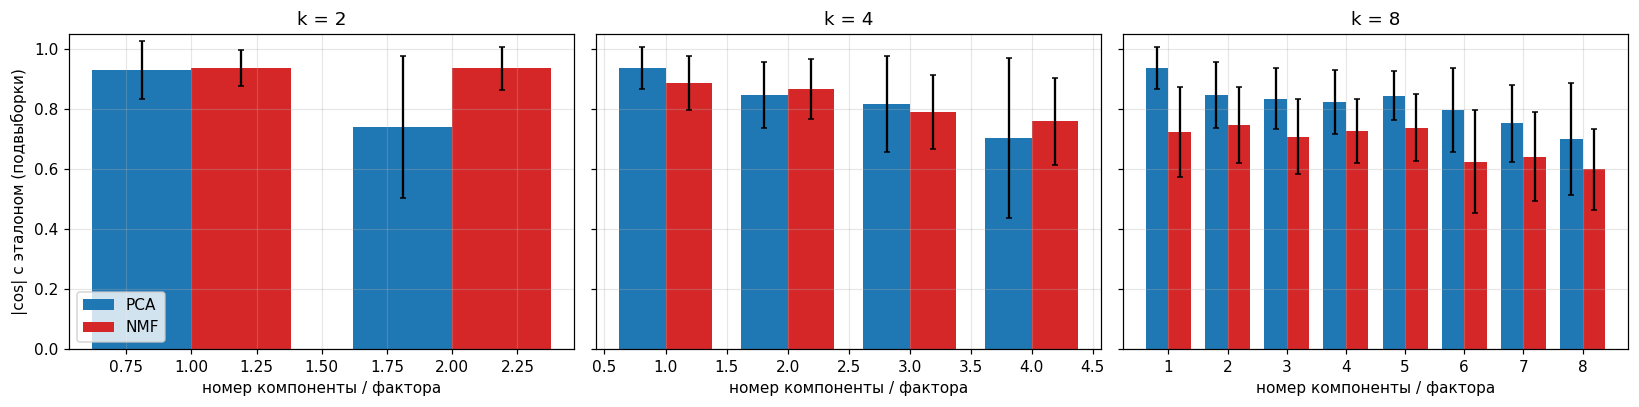

Собственные значения PCA (доли дисперсии): [0.134 0.107 0.097 0.081 0.075 0.061 0.06  0.054 0.05  0.046 0.044 0.042
 0.04  0.038 0.035 0.035]


In [10]:
def match_cos(Href, H, center=True):
    # |cos| между факторами после оптимального сопоставления. center=True вычитает среднюю нагрузку по преобразователям:
    # у неотрицательных факторов косинус «сырых» векторов завышен общей положительной составляющей.
    Hr, Hh = (Href - Href.mean(1, keepdims=True), H - H.mean(1, keepdims=True)) if center else (Href, H)
    A = np.abs((Hr / np.linalg.norm(Hr, axis=1, keepdims=True)) @ (Hh / np.linalg.norm(Hh, axis=1, keepdims=True)).T)
    r, c = linear_sum_assignment(-A); return A[r, c]
def offdiag_cos(H, center=True):
    Hh = H - H.mean(1, keepdims=True) if center else H
    A = np.abs((Hh / np.linalg.norm(Hh, axis=1, keepdims=True)) @ (Hh / np.linalg.norm(Hh, axis=1, keepdims=True)).T)
    return A[np.triu_indices(len(H), 1)].mean()
def subspace_sim(Uref, U):
    return np.linalg.norm(Uref @ U.T, 'fro') ** 2 / Uref.shape[0]

ub = np.unique(gtr); rng = np.random.default_rng(SEED); B = 30
ref = {(m, k): fit_recon(m, k, Ztr)[1] for m in ['PCA', 'NMF'] for k in [2, 4, 8]}
boot = {key: [] for key in ref}; boot_sub = {k: [] for k in [2, 4, 8]}
for b in range(B):
    keep = rng.choice(ub, int(0.7 * len(ub)), replace=False); Zb = Ztr[np.isin(gtr, keep)]
    for k in [2, 4, 8]:
        Hp = fit_recon('PCA', k, Zb)[1]; boot[('PCA', k)].append(match_cos(ref[('PCA', k)], Hp)); boot_sub[k].append(subspace_sim(ref[('PCA', k)], Hp))
        Hn = fit_recon('NMF', k, Zb)[1]; boot[('NMF', k)].append(match_cos(ref[('NMF', k)], Hn))
ev = PCA(16).fit(Ztr).explained_variance_
rows = []
for k in [2, 4, 8]:
    P_ = np.array(boot[('PCA', k)]); N_ = np.array(boot[('NMF', k)])
    N_raw = np.mean([match_cos(ref[('NMF', k)], fit_recon('NMF', k, Ztr[np.isin(gtr, rng.choice(ub, int(0.7 * len(ub)), replace=False))])[1], center=False).mean() for _ in range(10)])
    rows.append({'k': k, 'PCA: сходство подпространств': f'{np.mean(boot_sub[k]):.3f} ± {np.std(boot_sub[k]):.3f}', 'случайный уровень (k/16)': round(k / 16, 3),
                 'PCA: |cos| компонент, min': round(P_.mean(0).min(), 3), 'NMF: |cos| факторов (центр.), min': round(N_.mean(0).min(), 3),
                 'NMF: |cos| (центр.), среднее': round(N_.mean(), 3), 'NMF: |cos| «сырой», среднее': round(N_raw, 3),
                 'NMF: |cos| разных факторов (центр.)': round(offdiag_cos(ref[('NMF', k)]), 3), 'PCA: зазор λk/λk+1': round(ev[k - 1] / ev[k], 3)})
display(pd.DataFrame(rows).set_index('k').T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, k in zip(ax, [2, 4, 8]):
    P_ = np.array(boot[('PCA', k)]); N_ = np.array(boot[('NMF', k)]); x = np.arange(1, k + 1); w = .38
    a.bar(x - w / 2, P_.mean(0), w, yerr=P_.std(0), capsize=2, label='PCA', color='tab:blue')
    a.bar(x + w / 2, N_.mean(0), w, yerr=N_.std(0), capsize=2, label='NMF', color='tab:red')
    a.set_title(f'k = {k}'); a.set_xlabel('номер компоненты / фактора'); a.set_ylim(0, 1.05)
ax[0].set_ylabel('|cos| с эталоном (подвыборки)'); ax[0].legend(); plt.tight_layout(); plt.show()
print('Собственные значения PCA (доли дисперсии):', (ev / ev.sum()).round(3))

In [11]:
# разные случайные старты NMF на одних и тех же данных
for k in [2, 4, 8]:
    Hs, errs = [], []
    for s in range(10):
        m = NMF(k, init='random', solver='cd', max_iter=3000, tol=1e-7, random_state=s).fit(Ztr)
        Hs.append(m.components_); errs.append(np.sqrt(((Ztr - m.inverse_transform(m.transform(Ztr))) ** 2).sum() / (Ztr ** 2).sum()))
    cs = np.array([match_cos(Hs[0], H) for H in Hs[1:]])
    print(f'k={k}: относительная ошибка по стартам {np.min(errs):.4f}…{np.max(errs):.4f}; |cos| (центр.) факторов с первым стартом: среднее {cs.mean():.3f}, min {cs.min():.3f}')

k=2: относительная ошибка по стартам 0.0670…0.0670; |cos| (центр.) факторов с первым стартом: среднее 1.000, min 1.000
k=4: относительная ошибка по стартам 0.0582…0.0582; |cos| (центр.) факторов с первым стартом: среднее 0.781, min 0.156
k=8: относительная ошибка по стартам 0.0434…0.0434; |cos| (центр.) факторов с первым стартом: среднее 0.644, min 0.213


k=8: относительная ошибка по стартам 0.0434…0.0434; |cos| (центр.) факторов с первым стартом: среднее 0.644, min 0.213


In [20]:
# подпространства NMF между стартами и сравнение с SVD без центрирования
def basis(H):
    q, _ = np.linalg.qr(H.T); return q.T            # ортонормированный базис строк

_, _, Vt = np.linalg.svd(Ztr, full_matrices=False)
for k in [4, 8]:
    Hs = [NMF(k, init='random', solver='cd', max_iter=3000, tol=1e-7, random_state=s).fit(Ztr).components_ for s in range(10)]
    B0 = basis(Hs[0]); sims = [subspace_sim(B0, basis(H)) for H in Hs[1:]]
    print(f'k={k}: сходство подпространств NMF между стартами: min {min(sims):.3f} '
          f'| NMF vs SVD без центр.: {subspace_sim(Vt[:k], B0):.4f} | случайный уровень {k/16:.3f}')

k=4: сходство подпространств NMF между стартами: min 1.000 | NMF vs SVD без центр.: 1.0000 | случайный уровень 0.250
k=8: сходство подпространств NMF между стартами: min 1.000 | NMF vs SVD без центр.: 1.0000 | случайный уровень 0.500


**Что видно.** 
1) Подпространство, натянутое на k главных компонент, воспроизводится заметно выше случайного уровня k/16 (0.80, 0.89, 0.93 против 0.125, 0.25, 0.5), а отдельные компоненты — хуже (|cos| ≥ 0.70 в среднем, но при зазоре λ_k/λ_{k+1} ≈ 1.08–1.10 направления «вращаются» внутри подпространства).
2) (2) Для NMF «сырой» косинус (≈ 0.90–1.0) завышен: факторы неотрицательны и все почти параллельны единичному вектору. После вычитания средней нагрузки сходство факторов падает до 0.94, 0.83, 0.69 (min 0.94, 0.76, 0.60) при k = 2, 4, 8; при k = 2 два центрированных фактора почти коллинеарны (между разными факторами 0.96), поэтому эта мера там малоинформативна, а при k = 4 и 8 она заметно выше уровня между разными факторами (0.33 и 0.17).
3) Разные случайные старты NMF дают одну и ту же ошибку и **одно и то же подпространство** (сходство 1.000, совпадает с подпространством SVD без центрирования), но разные базисы факторов (min сходство 0.16 при k = 4, 0.21 при k = 8). Неотрицательное разложение определено лишь с точностью до вращения внутри подпространства, поэтому интерпретировать можно подпространство, но не отдельный фактор. Устойчивость базиса падает с ростом k.

## 7. Тепловые карты нагрузок 16 преобразователей

Строки — преобразователи (индексы 1…16), столбцы — компоненты PCA (знак условный) и неотрицательные факторы NMF (нормированы на единичную длину; упорядочены по вкладу ‖w‖·‖h‖). **Номер преобразователя — произвольная метка**, поэтому закономерность по оси «строки» не следует читать как пространственную.

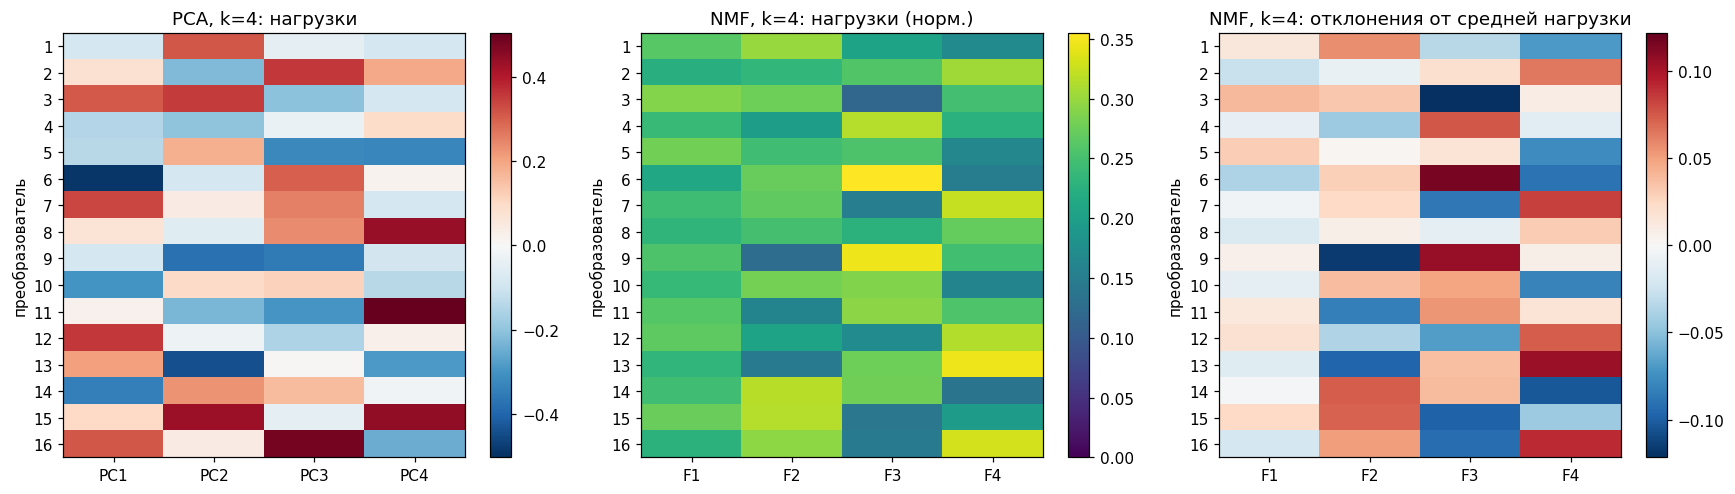

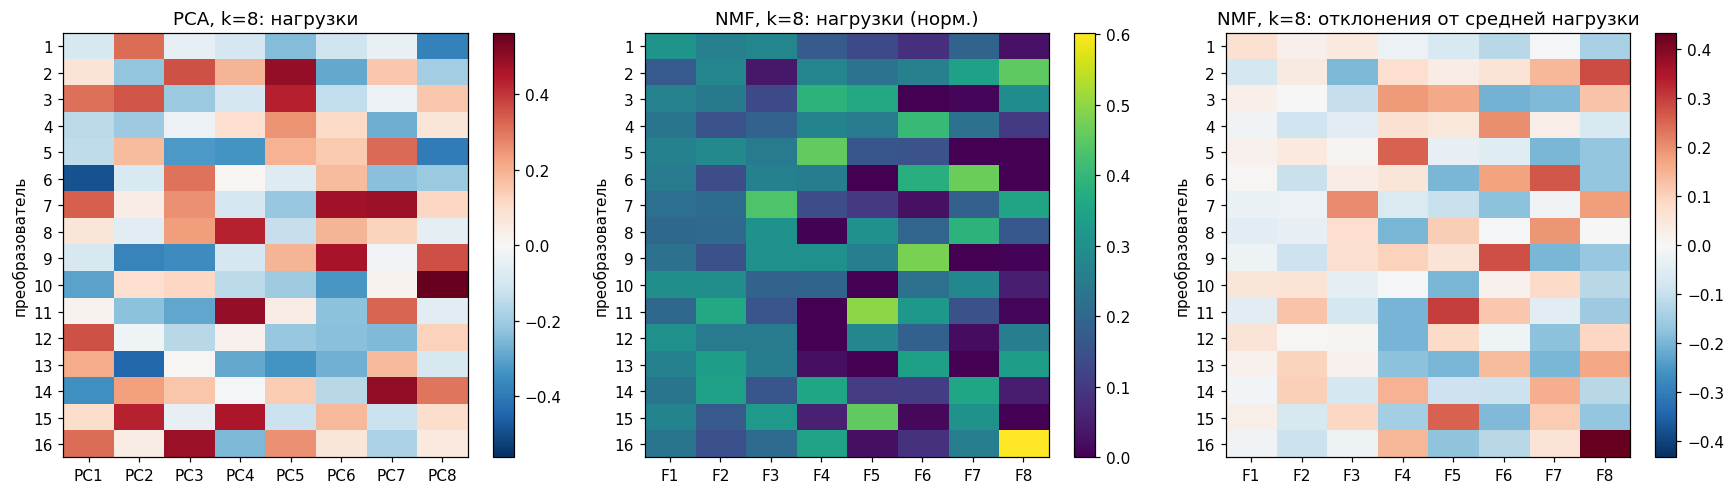

In [12]:
def order_nmf(m_k):
    f, H = fit_recon('NMF', m_k, Ztr)
    nm = NMF(m_k, init='nndsvda', solver='cd', max_iter=2000, tol=1e-6, random_state=0).fit(Ztr)
    W = nm.transform(Ztr); en = np.linalg.norm(W, axis=0) * np.linalg.norm(nm.components_, axis=1); o = np.argsort(-en)
    return nm, o, en
def heat(k):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    pca = PCA(k).fit(Ztr); L = pca.components_.copy()
    L *= np.sign(L.sum(1, keepdims=True) + 1e-12)                       # знак: суммарная нагрузка ≥ 0
    v = np.abs(L).max(); im0 = ax[0].imshow(L.T, cmap='RdBu_r', vmin=-v, vmax=v, aspect='auto')
    ax[0].set_title(f'PCA, k={k}: нагрузки'); ax[0].set_xticks(range(k)); ax[0].set_xticklabels([f'PC{i+1}' for i in range(k)]); plt.colorbar(im0, ax=ax[0])
    nm, o, en = order_nmf(k); Hn = nm.components_[o] / np.linalg.norm(nm.components_[o], axis=1, keepdims=True)
    im1 = ax[1].imshow(Hn.T, cmap='viridis', aspect='auto', vmin=0)
    ax[1].set_title(f'NMF, k={k}: нагрузки (норм.)'); ax[1].set_xticks(range(k)); ax[1].set_xticklabels([f'F{i+1}' for i in range(k)]); plt.colorbar(im1, ax=ax[1])
    D = Hn - Hn.mean(1, keepdims=True); v2 = np.abs(D).max(); im2 = ax[2].imshow(D.T, cmap='RdBu_r', vmin=-v2, vmax=v2, aspect='auto')
    ax[2].set_title(f'NMF, k={k}: отклонения от средней нагрузки'); ax[2].set_xticks(range(k)); ax[2].set_xticklabels([f'F{i+1}' for i in range(k)]); plt.colorbar(im2, ax=ax[2])
    for a in ax: a.set_yticks(range(16)); a.set_yticklabels(range(1, 17)); a.set_ylabel('преобразователь'); a.grid(False)
    plt.tight_layout(); plt.show()
    return L, Hn
L4, H4 = heat(4); L8, H8 = heat(8)

In [13]:
# локализованность факторов: «число эффективно задействованных преобразователей» (участие), 16 = равномерно, 1 = один преобразователь
pr = lambda h: (h ** 2).sum() ** 2 / (h ** 4).sum()
print('Участие (из 16), PCA k=4:', [round(pr(r), 1) for r in L4]); print('Участие (из 16), NMF k=4:', [round(pr(r), 1) for r in H4])
print('Участие (из 16), PCA k=8:', [round(pr(r), 1) for r in L8]); print('Участие (из 16), NMF k=8:', [round(pr(r), 1) for r in H8])

Участие (из 16), PCA k=4: [7.8, 7.7, 8.1, 6.0]
Участие (из 16), NMF k=4: [15.6, 13.6, 12.3, 12.5]
Участие (из 16), PCA k=8: [7.8, 7.7, 8.1, 6.1, 7.7, 7.7, 6.6, 5.8]
Участие (из 16), NMF k=8: [14.7, 12.1, 10.8, 8.2, 6.8, 7.4, 8.0, 4.7]


## 8. Физический вопрос: общий режим и режим неравномерности

Определим для каждой компоновки: суммарную мощность `Powerall` и **неравномерность** CV = sd(Pi)/mean(Pi) по 16 преобразователям (эти величины — для интерпретации, в факторное пространство не входят). Смотрим на отложенных компоновках: (а) какая доля разброса приходится на «общий» вектор (1,…,1)/4; (б) с какими факторами связаны `Powerall` и CV.

In [14]:
cv_ = Zte.std(1) / Zte.mean(1); pa_te = pa[is_te]
u = np.ones(16) / 4; S = np.cov(Ztr.T)
print('Доля разброса вокруг среднего вдоль общего вектора (1,…,1)/4: %.3f (среднее на одну из 16 компонент: %.3f)' % (u @ S @ u / np.trace(S), 1 / 16))
pca8 = PCA(8).fit(Ztr); cosu = np.abs(pca8.components_ @ u)
print('|cos| компонент PC1…PC8 с общим вектором:', cosu.round(2))
print('corr(Powerall, CV) на тесте: %.2f' % np.corrcoef(pa_te, cv_)[0, 1])

def corr_table(k):
    pca = PCA(k).fit(Ztr); s = pca.transform(Zte)
    nm, o, _ = order_nmf(k); w = nm.transform(Zte)[:, o]
    rows = []
    for j in range(k):
        rows.append({'фактор': f'PC{j+1}', 'corr с Powerall': np.corrcoef(s[:, j], pa_te)[0, 1], 'corr с CV': np.corrcoef(s[:, j], cv_)[0, 1]})
    for j in range(k):
        rows.append({'фактор': f'NMF F{j+1}', 'corr с Powerall': np.corrcoef(w[:, j], pa_te)[0, 1], 'corr с CV': np.corrcoef(w[:, j], cv_)[0, 1],
                     'участие': round(pr(nm.components_[o][j]), 1), '|cos| с (1,…,1)/4': abs(nm.components_[o][j] @ u) / np.linalg.norm(nm.components_[o][j])})
    return pd.DataFrame(rows).set_index('фактор').round(2)
corr_table(4)

Доля разброса вокруг среднего вдоль общего вектора (1,…,1)/4: 0.043 (среднее на одну из 16 компонент: 0.062)
|cos| компонент PC1…PC8 с общим вектором: [0.05 0.01 0.12 0.07 0.12 0.01 0.24 0.12]
corr(Powerall, CV) на тесте: -0.78


,corr с Powerall,corr с CV,участие,"|cos| с (1,…,1)/4"
фактор,,,,
PC1,0.11,-0.10,NaN,NaN
PC2,-0.01,-0.00,NaN,NaN
PC3,-0.08,0.07,NaN,NaN
PC4,-0.08,0.10,NaN,NaN
NMF F1,0.05,-0.03,15.6,1.00
NMF F2,0.02,-0.02,13.6,0.97
NMF F3,-0.00,0.00,12.3,0.96
NMF F4,0.07,-0.07,12.5,0.96


In [15]:
# насколько факторная модель воспроизводит суммарную мощность и неравномерность (на отложенных компоновках)
rows = []
for k in [2, 4, 8, 16]:
    for m in ['PCA', 'NMF']:
        Zh = fit_recon(m, k, Ztr)[0](Zte); tot_h = Zh.sum(1); cv_h = Zh.std(1) / Zh.mean(1)
        rows.append({'k': k, 'метод': m, 'corr(ΣP̂, Powerall)': np.corrcoef(tot_h, pa_te)[0, 1], 'corr(CV̂, CV)': np.corrcoef(cv_h, cv_)[0, 1]})
pd.DataFrame(rows).set_index(['k', 'метод']).round(2)

corr(ΣP̂, Powerall)  corr(CV̂, CV)
k  метод                                    
2  PCA                   0.11           0.24
   NMF                   1.00           0.21
4  PCA                   0.15           0.25
   NMF                   1.00           0.24
8  PCA                   0.32           0.51
   NMF                   1.00           0.51
16 PCA                   1.00           1.00
   NMF                   1.00           1.00

In [16]:
corr_table(8)

,corr с Powerall,corr с CV,участие,"|cos| с (1,…,1)/4"
фактор,,,,
PC1,0.11,-0.10,NaN,NaN
PC2,-0.01,-0.00,NaN,NaN
PC3,-0.08,0.07,NaN,NaN
PC4,-0.08,0.10,NaN,NaN
PC5,0.17,-0.10,NaN,NaN
PC6,0.13,-0.09,NaN,NaN
PC7,-0.20,0.12,NaN,NaN
PC8,-0.08,0.04,NaN,NaN
NMF F1,-0.04,0.00,14.7,0.99


**Выводы по H1 и H2.** *Общий режим.* В PCA (среднее вычтено) общий вектор (1,…,1)/4 **не выделяется**: на него приходится 4.3 % разброса (меньше среднего 6.2 % на компоненту), |cos| ведущих компонент с ним ≤ 0.24; счёт ни одной компоненты не коррелирует с `Powerall`. Причина: суммарная мощность оптимизированных компоновок почти не меняется и слегка «зажата» отрицательными корреляциями между преобразователями. Зато **неотрицательные факторы NMF почти параллельны единичному вектору** (|cos| ≥ 0.96 при k = 4, участие 12–16 преобразователей из 16): они задают средний *уровень* мощности ≈ 0.93 на преобразователь, и восстановленная суммарная мощность ΣP̂ коррелирует с `Powerall` на уровне 1.00 уже при k = 2 (у PCA — 0.11, 0.15, 0.32 при k = 2, 4, 8). Значит, H1 верна только для общего *уровня*, а не для колебаний суммарной мощности, и только в безцентровой модели. *Неравномерность.* Коэффициент вариации CV сильно связан с суммарной мощностью (corr = −0.78: более равномерные компоновки дают большую суммарную мощность), но ни один отдельный фактор с CV не связан (|r| ≤ 0.2); восстановление CV по факторам слабое (corr 0.2–0.25 при k = 2, 4 и 0.5 при k = 8). То есть режим неравномерности — нелинейная характеристика, распределённая по многим компонентам; H2 как «один фактор» не подтверждается.

## 9. Проверка пространственной интерпретации по координатам

Задание прямо запрещает называть факторы пространственными модами без проверки по координатам. Координаты используем **только здесь**, для интерпретации.

1. Зависит ли мощность преобразователя от его собственного положения (x_i, y_i)?
2. Объясняют ли факторы по индексам эту зависимость (остаток реконструкции не должен коррелировать с координатами, если факторы пространственны)?
3. Что будет, если упорядочить преобразователи по положению вдоль направления градиента мощности (представление, не зависящее от произвольных меток)?

In [17]:
Xtr_c, Ytr_c, Xte_c, Yte_c = Xc[~is_te], Yc[~is_te], Xc[is_te], Yc[is_te]
A = lambda x, y: np.c_[x.ravel(), y.ravel(), np.ones(x.size)]
b = np.linalg.lstsq(A(Xtr_c, Ytr_c), Ztr.ravel(), rcond=None)[0]
pred = (A(Xte_c, Yte_c) @ b).reshape(Zte.shape)
print('P_i ~ собственные координаты: corr(P,x) = %.2f, corr(P,y) = %.2f; линейная модель по (x_i, y_i), R² на тесте = %.2f' %
      (np.corrcoef(Xte_c.ravel(), Zte.ravel())[0, 1], np.corrcoef(Yte_c.ravel(), Zte.ravel())[0, 1], 1 - ((Zte - pred) ** 2).sum() / ((Zte - Zte.mean()) ** 2).sum()))
print('Для сравнения: PCA по индексам при k = 8 объясняет R²_rec ≈ %.2f' % te_curve['PCA'][7])

rows = []
for k in [2, 4, 8]:
    for m in ['PCA', 'NMF']:
        f, _ = fit_recon(m, k, Ztr); R = Zte - f(Zte)
        rows.append({'k': k, 'метод': m, 'corr(остаток, x_i)': np.corrcoef(Xte_c.ravel(), R.ravel())[0, 1], 'corr(остаток, y_i)': np.corrcoef(Yte_c.ravel(), R.ravel())[0, 1]})
pd.DataFrame(rows).set_index(['k', 'метод']).round(2)

P_i ~ собственные координаты: corr(P,x) = 0.54, corr(P,y) = -0.57; линейная модель по (x_i, y_i), R² на тесте = 0.62
Для сравнения: PCA по индексам при k = 8 объясняет R²_rec ≈ 0.63


corr(остаток, x_i)  corr(остаток, y_i)
k метод                                        
2 PCA                  0.50               -0.50
  NMF                  0.53               -0.55
4 PCA                  0.40               -0.42
  NMF                  0.47               -0.47
8 PCA                  0.25               -0.27
  NMF                  0.32               -0.30

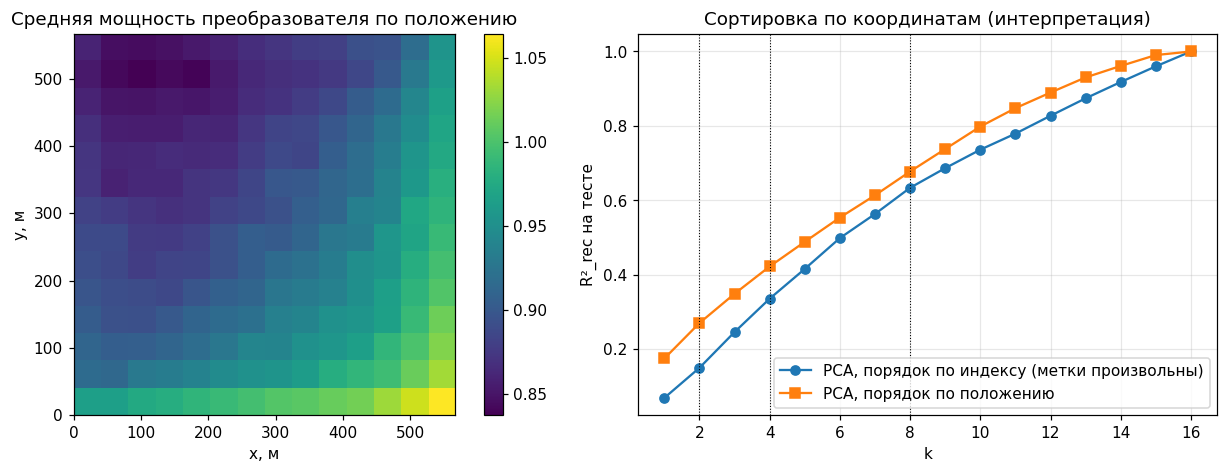

Средняя мощность по рангу вдоль градиента (рост от первого к последнему): [0.85 0.85 0.86 0.87 0.88 0.89 0.91 0.92 0.93 0.94 0.95 0.96 0.97 0.99
 1.01 1.06]
R²_rec на тесте при k=2,4,8: по индексу [0.15  0.336 0.634] | по положению [0.27  0.422 0.678]


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
nb_ = 14; xe = np.linspace(0, 566, nb_ + 1)
xi = np.clip(np.digitize(Xc.ravel(), xe) - 1, 0, nb_ - 1); yi = np.clip(np.digitize(Yc.ravel(), xe) - 1, 0, nb_ - 1)
M = np.full((nb_, nb_), np.nan); cnt = np.zeros((nb_, nb_))
for i in range(nb_):
    for j in range(nb_):
        s = (xi == i) & (yi == j); cnt[j, i] = s.sum()
        if s.sum() > 30: M[j, i] = Z.ravel()[s].mean()
im = ax[0].imshow(M, origin='lower', extent=[0, 566, 0, 566], cmap='viridis'); plt.colorbar(im, ax=ax[0]); ax[0].grid(False)
ax[0].set_xlabel('x, м'); ax[0].set_ylabel('y, м'); ax[0].set_title('Средняя мощность преобразователя по положению')
# упорядочение по положению вдоль градиента u = b0 x + b1 y
gr = b[0] * Xc + b[1] * Yc; o = np.argsort(gr, axis=1); Zs = np.take_along_axis(Z, o, 1)
Zs_tr, Zs_te = Zs[~is_te], Zs[is_te]; mus = Zs_tr.mean(0)
pi = [rec_metrics(Zte, fit_recon('PCA', k, Ztr)[0](Zte), mu_tr)['R2_rec'] for k in ks]
ps = [rec_metrics(Zs_te, fit_recon('PCA', k, Zs_tr)[0](Zs_te), mus)['R2_rec'] for k in ks]
ax[1].plot(ks, pi, 'o-', label='PCA, порядок по индексу (метки произвольны)'); ax[1].plot(ks, ps, 's-', label='PCA, порядок по положению')
for kk in [2, 4, 8]: ax[1].axvline(kk, c='k', ls=':', lw=.7)
ax[1].set_xlabel('k'); ax[1].set_ylabel('R²_rec на тесте'); ax[1].legend(); ax[1].set_title('Сортировка по координатам (интерпретация)')
plt.tight_layout(); plt.show()
print('Средняя мощность по рангу вдоль градиента (рост от первого к последнему):', Zs.mean(0).round(2))
print('R²_rec на тесте при k=2,4,8: по индексу', np.round([pi[1], pi[3], pi[7]], 3), '| по положению', np.round([ps[1], ps[3], ps[7]], 3))

**Выводы по H3.** Мощность преобразователя заметно зависит от **собственных координат** (линейная модель по x_i, y_i объясняет около 60 % разброса мощностей), но факторы по индексам эту зависимость не воспроизводят: остатки реконструкции остаются коррелированными с координатами. Причина — номер преобразователя не привязан к положению. Поэтому нагрузки PCA/NMF по индексам **нельзя** называть пространственными модами. Мощность растёт вдоль выделенного направления (от ≈ 0.85 до ≈ 1.06). Переход к представлению «по положению» улучшает компактность лишь умеренно: R²_rec на тесте при k = 2, 4, 8 равен 0.27, 0.42, 0.68 против 0.15, 0.34, 0.63 по индексу, то есть спектр остаётся пологим и после упорядочения. H3 подтверждена.

## 10. Вторая акватория (Perth)

Тот же протокол для сценария Perth (5 000 компоновок, блочный тест). Для переноса главные направления Sydney применяются к отложенным компоновкам Perth после перецентрирования (сдвиг среднего уровня убирается).

In [19]:
rawP = load('Perth'); idxP, gP, teP = make_sample(rawP)
ZP = rawP.iloc[idxP][cols_P].values / 1e5; ZPtr, ZPte = ZP[~teP], ZP[teP]; muP = ZPtr.mean(0)
rows = []
for k in [2, 4, 8]:
    VS = PCA(k).fit(Ztr).components_                                  # главные направления Sydney
    ZhS = (ZPte - muP) @ VS.T @ VS + muP                              # применяем к Perth после перецентрирования (убираем сдвиг уровня)
    for m in METHODS:
        fP, _ = fit_recon(m, k, ZPtr)
        rows.append({'k': k, 'метод': m, 'Perth→Perth R²_rec': rec_metrics(ZPte, fP(ZPte), muP)['R2_rec'], 'Sydney→Sydney R²_rec': rec_metrics(Zte, fit_recon(m, k, Ztr)[0](Zte), mu_tr)['R2_rec'],
                     'направления Sydney на Perth (только PCA)': rec_metrics(ZPte, ZhS, muP)['R2_rec'] if m == 'PCA' else np.nan})
display(pd.DataFrame(rows).set_index(['k', 'метод']).round(3))
print('Средняя мощность на преобразователь: Sydney %.3f, Perth %.3f (сдвиг уровня). Перенос оценён только для PCA с перецентрированием: у NMF/SVD без центрирования сдвиг уровня подмешивается в ошибку.' % (Ztr.mean(), ZPtr.mean()))
for k in [2, 4, 8]:
    print(f'k={k}: сходство подпространств PCA Sydney–Perth = {subspace_sim(fit_recon("PCA", k, Ztr)[1], fit_recon("PCA", k, ZPtr)[1]):.3f} (для случайных подпространств ≈ {k/16:.2f})')
pP = PCA(16).fit(ZPtr); print('Perth: доли дисперсии PCA', pP.explained_variance_ratio_.round(3)[:8], '| накопл. при 2,4,8:', pP.explained_variance_ratio_.cumsum()[[1, 3, 7]].round(3))

Perth→Perth R²_rec  Sydney→Sydney R²_rec  \
k метод                                                        
2 PCA                            0.177                 0.150   
  SVD (без центр.)               0.183                 0.113   
  NMF                            0.183                 0.113   
4 PCA                            0.322                 0.336   
  SVD (без центр.)               0.320                 0.291   
  NMF                            0.320                 0.291   
8 PCA                            0.565                 0.634   
  SVD (без центр.)               0.561                 0.608   
  NMF                            0.562                 0.608   

                    направления Sydney на Perth (только PCA)  
k метод                                                       
2 PCA                                                  0.125  
  SVD (без центр.)                                       NaN  
  NMF                                                    NaN  
4 PCA                                                  0.248  
  SVD (без центр.)                                       NaN  
  NMF                                                    NaN  
8 PCA                                                  0.488  
  SVD (без центр.)                                       NaN  
  NMF                                                    NaN

Средняя мощность на преобразователь: Sydney 0.929, Perth 0.870 (сдвиг уровня). Перенос оценён только для PCA с перецентрированием: у NMF/SVD без центрирования сдвиг уровня подмешивается в ошибку.
k=2: сходство подпространств PCA Sydney–Perth = 0.119 (для случайных подпространств ≈ 0.12)
k=4: сходство подпространств PCA Sydney–Perth = 0.191 (для случайных подпространств ≈ 0.25)
k=8: сходство подпространств PCA Sydney–Perth = 0.514 (для случайных подпространств ≈ 0.50)
Perth: доли дисперсии PCA [0.111 0.08  0.069 0.068 0.067 0.064 0.061 0.06 ] | накопл. при 2,4,8: [0.191 0.328 0.579]


## 11. Итоги

### Главный ответ

**Нет, распределение мощности между 16 преобразователями нельзя описать малым числом факторов.** Чтобы восстановить 90 % разброса мощностей вокруг среднего, нужно 14 факторов из 16, то есть почти все.

### Что мы делали

Взяли мощности 16 преобразователей из сценария Sydney (5 000 компоновок) и попробовали сжать их до 2, 4 и 8 факторов двумя методами: PCA и NMF. Затем смотрели, насколько хорошо по этим факторам восстанавливаются исходные мощности на компоновках, которых модель не видела, и насколько факторы устойчивы. Координаты преобразователей и суммарную мощность `Powerall` в факторы не включали, использовали только для интерпретации.

**Как читать метрику.** R²_rec — это доля разброса мощностей вокруг среднего, которую удалось восстановить. 0 означает «не лучше среднего», 1 означает «восстановили идеально».

### 1. Насколько хорошо факторы восстанавливают мощности

| Число факторов | PCA: обучение / CV / тест | NMF: обучение / CV / тест |
|---|---|---|
| 2 | 0.241 / 0.216 / 0.150 | 0.177 / 0.163 / 0.113 |
| 4 | 0.419 / 0.382 / 0.336 | 0.380 / 0.348 / 0.291 |
| 8 | 0.669 / 0.645 / 0.634 | 0.656 / 0.623 / 0.608 |

- **Резкого «локтя» нет.** Каждый следующий фактор добавляет немного: от ≈ 0.10 у первых до ≈ 0.04 у последних. Так происходит потому, что мощности разных преобразователей почти не связаны между собой (средняя корреляция −0.02), а вклад компонент в разброс убывает плавно (13 %, 11 %, 10 %, …).
- **Переобучения нет.** Разница между обучением и тестом небольшая: при 8 факторах 0.03 (PCA) и 0.05 (NMF), при 2 и 4 — 0.06–0.09. Низкое качество объясняется самими данными, а не нехваткой выборки.
- **PCA чуть лучше NMF.** Но дело не в качестве метода: PCA вычитает среднее и «бесплатно» получает лишний параметр. Если сравнивать NMF с SVD без вычитания среднего (того же ранга), ошибка совпадает. Условие неотрицательности в этих данных ничего не меняет.
- **Относительная ошибка (≈ 4.5–7 %) вводит в заблуждение:** она мала только из-за большого среднего (≈ 0.93). Поэтому мы смотрим на R²_rec.

### 2. Устойчивы ли факторы

Если взять другую часть данных и заново найти факторы, получим ли мы те же самые? Сравнивали с эталонным решением (сходство 1 означает полное совпадение).

| | 2 фактора | 4 фактора | 8 факторов |
|---|---|---|---|
| PCA: сходство набора факторов целиком | 0.80 | 0.89 | 0.93 |
| уровень сходства «просто случайно» | 0.125 | 0.25 | 0.5 |
| NMF: сходство отдельных факторов | 0.94 | 0.83 | 0.69 |

- **PCA.** Набор главных направлений в целом воспроизводится заметно лучше случайного. Отдельные компоненты устойчивы хуже (сходство ≥ 0.70): их собственные значения почти равны (отношение соседних 1.08–1.10), поэтому внутри этого набора направления «вращаются».
- **NMF.** При разных случайных стартах получаются **одинаковая ошибка и один и тот же набор направлений** (сходство 1.000), но **разные факторы** (минимальное сходство 0.16 при 4 факторах и 0.21 при 8). Иными словами, NMF определяет только «плоскость», а какие именно оси выбрать внутри неё, зависит от старта. Поэтому надёжно интерпретировать можно набор факторов целиком, но не каждый фактор по отдельности.
- **Про меру сходства.** Все факторы NMF почти параллельны вектору (1,…,1), поэтому обычный косинус у них завышен (≈ 0.90–1.0). Мы вычитаем среднюю нагрузку. При 2 факторах такая мера мало что говорит: два фактора почти совпадают по направлению (0.96).
- **Между акваториями факторы не переносятся.** Сходство наборов PCA для Sydney и Perth 0.12 / 0.19 / 0.51, то есть на уровне случайного (0.125 / 0.25 / 0.5).

### 3. Что это значит физически

Вопрос из задания: проявляются ли общий режим мощности фермы и режим неравномерного распределения?

| Ожидание | Что получили | Вывод |
|---|---|---|
| **Общий режим:** есть фактор «все преобразователи вместе» | В NMF есть, но он отражает **средний уровень** мощности, а не её колебания. В PCA общий режим не выделяется | Частично |
| **Неравномерность:** есть фактор перераспределения между преобразователями | Отдельного фактора нет | Не подтверждено |
| **Индекс ≠ положение:** факторы по номерам не пространственные моды | Подтверждено (см. ниже) | Подтверждено |

**Общий режим.**
- Факторы NMF почти параллельны вектору (1,…,1) (сходство ≥ 0.96 при 4 факторах), и восстановленная суммарная мощность совпадает с `Powerall` (корреляция 1.00 уже при 2 факторах). Это во многом механический результат: `Powerall` равна сумме всех мощностей, а базис NMF содержит почти единичный вектор, поэтому сумма сохраняется.
- В PCA среднее вычтено, и общий режим не виден: на него приходится 4.3 % разброса против 6.2 % в среднем на одну компоненту, а восстановленная сумма слабо совпадает с `Powerall` (0.11 / 0.15 / 0.32 при 2, 4, 8 факторах).

**Неравномерность.** Коэффициент вариации мощностей CV (разброс между преобразователями относительно среднего) сильно связан с суммарной мощностью (−0.78): более равномерные компоновки дают больше энергии. Но отдельный фактор за это не отвечает: корреляции счётов факторов с CV не выше 0.12, с `Powerall` не выше 0.20. По реконструкции CV воспроизводится слабо (0.2–0.25 при 2 и 4 факторах, 0.51 при 8).

**Пространственных мод нет.** Это требовалось проверить по координатам:
- мощность преобразователя зависит от его положения: R² ≈ 0.62, корреляция с x равна +0.54, с y равна −0.57;
- но остатки PCA и NMF остаются коррелированными с координатами (0.25–0.55 по модулю), то есть факторы эту зависимость не улавливают;
- причина проста: номер преобразователя ничего не говорит о его положении, это произвольная метка. Поэтому нагрузки факторов по номерам **нельзя** называть пространственными модами;
- если упорядочить преобразователи по положению вдоль направления роста мощности, качество растёт умеренно: R²_rec 0.27 / 0.42 / 0.68 против 0.15 / 0.34 / 0.63 при упорядочении по номеру.

### 4. Вторая акватория и особенности данных

- **Perth.** Картина та же: R²_rec для PCA 0.18 / 0.32 / 0.57. Направления, найденные на Sydney, на Perth работают хуже (0.13 / 0.25 / 0.49).
- **Компоновки получены оптимизацией,** поэтому соседние строки файла похожи (автокорреляция `Powerall` 0.66). Чтобы тест был честным, отложенные компоновки брали блоками по 1000 подряд идущих строк, а не случайными строками.
- **Разброс мощностей узкий** (≈ 7 % от среднего), по-видимому, потому что оптимизация собирает компоновки в области высокой мощности. Это ослабляет любую структуру «по номерам преобразователей».

### 5. Ограничения

- Координаты и `Powerall` использованы только для интерпретации. Единицы мощности в карточке набора не указаны (вероятно, Вт).
- Результаты получены на одном блочном разбиении (22 тестовых блока) и 30 подвыборках для проверки устойчивости.
- CV-значения немного зависят от версии sklearn (разбиение блоков по фолдам). Значения на тесте от неё не зависят.